<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C19_Notebook-23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

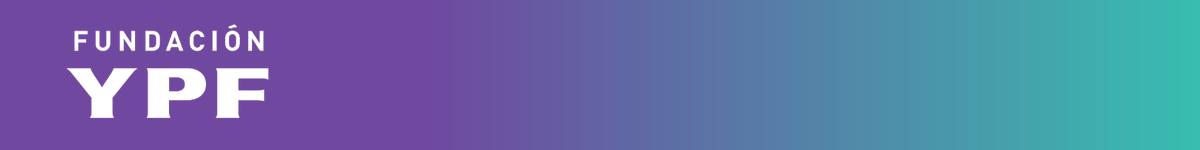

# Fundación YPF - Data Science

## Notebook 23: Aprendizaje NO supervisado, clustering con K-Means

### Índice de partes

* **Parte 0:** Preparación del entorno y carga de los datos
* **Parte 1:** Repaso de regresión y el problema de no tener etiqueta
* **Parte 2:** Datos sin etiquetas: exploración y búsqueda de grupos
* **Parte 3:** K-Means paso a paso
* **Parte 4:** K-Means con scikit-learn e interpretación de los clusters
* **Parte 5:** Primer vistazo a la reducción de dimensionalidad
* **Parte 6:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno y carga de los datos

Hasta ahora trabajamos con **aprendizaje supervisado**: siempre había una variable objetivo que queríamos predecir (una categoría o un valor). Hoy cambiamos de enfoque. En el **aprendizaje NO supervisado** los datos **no tienen etiqueta** y el objetivo es **encontrar patrones** en ellos.

En esta notebook vamos a:

* repasar regresión y ver por qué a veces no alcanza con predecir,
* explorar datos sin etiquetas y buscar grupos a simple vista,
* implementar **K-Means paso a paso** y luego usarlo con scikit-learn,
* interpretar los clusters que encontramos,
* dar un primer vistazo a la **reducción de dimensionalidad** con PCA.

**Dataset:** `clientes_mall.csv`. Son 200 clientes de un centro comercial, con su género, edad, ingreso anual (en miles de dólares) y un puntaje de gasto entre 1 y 100 que asigna el centro comercial según el comportamiento de compra.

**Problema:** el centro comercial quiere **segmentar a sus clientes** para diseñar acciones de marketing distintas para cada grupo. Nadie le dijo previamente a qué grupo pertenece cada cliente: tenemos que descubrirlo.

Antes de ejecutar, subí el archivo `clientes_mall.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [ ]:
# Si el archivo no está en Colab, se abre un cuadro para subirlo
if not os.path.exists("clientes_mall.csv"):
    from google.colab import files
    files.upload()

clientes = pd.read_csv("clientes_mall.csv")
clientes.head()

TypeError: 'NoneType' object is not subscriptable

La primera columna es un índice que quedó guardado al exportar el archivo y `CustomerID` es solo un identificador: ninguna de las dos aporta información sobre el cliente. Las eliminamos y traducimos los nombres de las columnas para trabajar más cómodos.

In [ ]:
clientes = clientes.drop(columns=["Unnamed: 0", "CustomerID"])
clientes.columns = ["Genero", "Edad", "Ingreso", "Puntaje"]

print("Forma del dataset:", clientes.shape)
print()
print("Valores faltantes por columna:")
print(clientes.isna().sum())

Hay valores faltantes en todas las columnas. Para esta práctica vamos a **trabajar solo con los clientes que tienen completos los datos numéricos** (`Edad`, `Ingreso` y `Puntaje`). Imputar con la mediana crearía muchos clientes idénticos "en el medio" de la nube de puntos, y eso distorsiona los grupos.

In [ ]:
datos = clientes.dropna(subset=["Edad", "Ingreso", "Puntaje"]).reset_index(drop=True)
print("Clientes con datos numéricos completos:", len(datos), "de", len(clientes))
datos.describe().round(1)

## Parte 1: Repaso de regresión y el problema de no tener etiqueta

Repasemos lo de la clase anterior con un experimento rápido. Supongamos que queremos **predecir el puntaje de gasto** a partir de la edad y el ingreso con una regresión lineal, evaluada con validación cruzada (clase 16) y la métrica R² (clase 15).

In [ ]:
X_reg = datos[["Edad", "Ingreso"]]
y_reg = datos["Puntaje"]

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
r2 = cross_val_score(LinearRegression(), X_reg, y_reg, cv=cv, scoring="r2")

print("R2 en cada partición:", r2.round(3))
print("R2 promedio:", r2.mean().round(3))

El R² promedio es **muy bajo**: con una recta, ni la edad ni el ingreso predicen bien el puntaje. Pero eso no significa que no haya estructura en los datos. Puede ser que **haya grupos de clientes con comportamientos distintos**, y que una única recta para todos no pueda capturarlos.

Cuando no tenemos una etiqueta que predecir, o cuando la relación entre variables no es una sola recta, el aprendizaje no supervisado nos ayuda a **descubrir esa estructura**. Dentro de este tipo de aprendizaje hay dos grandes familias:

* **Clustering:** agrupar las instancias parecidas entre sí. Es lo que haremos hoy.
* **Reducción de la dimensionalidad:** representar los datos con menos variables, reteniendo la mayor información posible. Le daremos un primer vistazo al final.

## Parte 2: Datos sin etiquetas: exploración y búsqueda de grupos

Antes de usar un algoritmo, **miramos los datos**. Con pocas variables podemos buscar grupos a simple vista.

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(datos["Edad"], bins=15, kde=True, ax=ax[0], color="#7030A0")
ax[0].set_title("Distribución de la edad")
sns.histplot(datos["Ingreso"], bins=15, kde=True, ax=ax[1], color="#7030A0")
ax[1].set_title("Distribución del ingreso anual (miles de dólares)")
sns.histplot(datos["Puntaje"], bins=15, kde=True, ax=ax[2], color="#7030A0")
ax[2].set_title("Distribución del puntaje de gasto")
plt.tight_layout()
plt.show()

In [ ]:
sns.pairplot(datos[["Edad", "Ingreso", "Puntaje"]], corner=True,
             plot_kws={"alpha": 0.6, "color": "#7030A0"}, diag_kws={"color": "#7030A0"})
plt.show()

**Preguntas para mirar los gráficos:**

* En el gráfico de `Ingreso` contra `Puntaje`, ¿ves **nubes de puntos separadas**? ¿Cuántas?
* ¿Alguna de las otras combinaciones de variables muestra grupos tan claros?

Hagamos zoom en el gráfico que más información da.

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=datos, x="Ingreso", y="Puntaje", color="#7030A0", alpha=0.7, s=60)
plt.title("Ingreso anual vs puntaje de gasto")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto (1 a 100)")
plt.tight_layout()
plt.show()

A simple vista aparecen varias nubes de puntos bien diferenciadas. Con dos variables nuestro ojo las encuentra, pero con diez o veinte variables ya no podríamos graficar. Necesitamos un **algoritmo que encuentre los grupos por nosotros**.

## Parte 3: K-Means paso a paso

**K-Means** separa los datos en un número **k** de clusters. Para eso busca **k centroides** (un punto "representante" por cada cluster) tal que cada instancia quede lo más cerca posible del centroide de su cluster.

El algoritmo es **iterativo**:

1. **Inicializar** los k centroides, por ejemplo eligiendo k instancias al azar.
2. **Asignar** cada instancia al centroide más cercano.
3. **Actualizar** cada centroide, calculando el promedio de las posiciones de las instancias de su cluster.
4. **Repetir** los pasos 2 y 3 hasta que los centroides ya no se muevan.

Lo implementamos con NumPy, usando solo dos variables (`Ingreso` y `Puntaje`) para poder graficar cada iteración.

In [ ]:
X2 = datos[["Ingreso", "Puntaje"]].to_numpy()


def asignar(X, centroides):
    # Paso 2: distancia de cada instancia a cada centroide y elección del más cercano
    distancias = np.linalg.norm(X[:, None, :] - centroides[None, :, :], axis=2)
    return distancias.argmin(axis=1)


def kmeans_manual(X, k, max_iter=20, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    # Paso 1: centroides iniciales elegidos al azar entre las instancias
    centroides = X[rng.choice(len(X), size=k, replace=False)]
    historial = [centroides.copy()]

    for _ in range(max_iter):
        etiquetas = asignar(X, centroides)                                   # Paso 2
        nuevos = np.array([X[etiquetas == j].mean(axis=0) if (etiquetas == j).any()
                           else centroides[j] for j in range(k)])            # Paso 3
        historial.append(nuevos.copy())
        if np.allclose(nuevos, centroides):                                  # Paso 4
            break
        centroides = nuevos

    return asignar(X, centroides), centroides, historial


etiquetas_manual, centroides_manual, historial = kmeans_manual(X2, k=5)
print("Iteraciones hasta converger:", len(historial) - 1)

Veamos cómo se mueven los centroides. Cada panel muestra la asignación de las instancias con los centroides de ese momento (las cruces).

In [ ]:
n = len(historial)
pasos = sorted(set([0, 1, 2, n - 1]))

fig, axes = plt.subplots(1, len(pasos), figsize=(5 * len(pasos), 4.5), sharex=True, sharey=True)
for ax, p in zip(axes, pasos):
    etiq = asignar(X2, historial[p])
    ax.scatter(X2[:, 0], X2[:, 1], c=etiq, cmap="tab10", alpha=0.7, s=40)
    ax.scatter(historial[p][:, 0], historial[p][:, 1], c="black", marker="X", s=200, edgecolor="white")
    ax.set_title("Centroides iniciales" if p == 0 else ("Resultado final" if p == n - 1 else (f"Después de {p} actualización" if p == 1 else f"Después de {p} actualizaciones")))
    ax.set_xlabel("Ingreso")
axes[0].set_ylabel("Puntaje")
plt.tight_layout()
plt.show()

**Importante:** la inicialización es aleatoria, así que **distintas semillas pueden dar resultados distintos**. Probemos con varias y comparemos qué tan "compactos" quedan los clusters. Esa medida se llama **inercia**: la suma de las distancias al cuadrado entre cada instancia y el centroide de su cluster. Cuanto menor, mejor.

In [ ]:
def inercia(X, etiquetas, centroides):
    return ((X - centroides[etiquetas]) ** 2).sum()

for semilla in range(6):
    etiq, cent, hist = kmeans_manual(X2, k=5, seed=semilla)
    print(f"Semilla {semilla}: inercia = {inercia(X2, etiq, cent):8.1f} | iteraciones = {len(hist) - 1}")

Algunas semillas terminan en soluciones peores (inercia mayor), porque el algoritmo quedó atrapado en un mínimo local. Por eso scikit-learn **repite la inicialización varias veces** (`n_init`) y se queda con la mejor.

## Parte 4: K-Means con scikit-learn e interpretación de los clusters

### 4.1 Escalar las variables

K-Means se basa en **distancias**, así que las variables con valores más grandes pesan más. Para que todas contribuyan por igual, las **escalamos** con `StandardScaler` (media 0 y desvío 1). Ahora usamos las tres variables numéricas.

In [ ]:
variables = ["Edad", "Ingreso", "Puntaje"]
escalador = StandardScaler()
X_esc = escalador.fit_transform(datos[variables])

pd.DataFrame(X_esc, columns=variables).describe().loc[["mean", "std"]].round(2)

### 4.2 Entrenar el modelo

Usamos `KMeans` con **k = 5**, que es lo que sugería el gráfico de `Ingreso` contra `Puntaje`. Con `n_init=10` el algoritmo prueba diez inicializaciones y conserva la mejor.

In [ ]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_esc)

datos["cluster"] = kmeans.labels_

print("Inercia:", round(kmeans.inertia_, 1))
print("Clientes por cluster:")
print(datos["cluster"].value_counts().sort_index())

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=datos, x="Ingreso", y="Puntaje", hue="cluster", palette="tab10", s=60, alpha=0.8)

# Los centroides están en el espacio escalado: los llevamos a las unidades originales
centroides = pd.DataFrame(escalador.inverse_transform(kmeans.cluster_centers_), columns=variables)
plt.scatter(centroides["Ingreso"], centroides["Puntaje"], c="black", marker="X", s=250, edgecolor="white", label="Centroides")

plt.title("Clusters de clientes con K-Means (k = 5)")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto (1 a 100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.3 Interpretar los clusters

Un cluster por sí solo es solo un número. El valor aparece cuando **lo describimos**: ¿qué tienen en común los clientes de cada grupo? Miramos el promedio de cada variable por cluster, y la composición por género (que **no usamos** para agrupar).

In [ ]:
perfil = datos.groupby("cluster")[variables].mean().round(1)
perfil["Clientes"] = datos["cluster"].value_counts().sort_index()
perfil

In [ ]:
genero = pd.crosstab(datos["cluster"], datos["Genero"], normalize="index").round(2)
genero

**Cómo interpretar la tabla.** Buscá en cada fila qué la distingue de las demás. Por ejemplo, un grupo con **ingreso alto y puntaje bajo** son clientes con mucho poder adquisitivo que gastan poco, un público al que quizás convenga dirigir acciones para estimular el consumo. Un grupo con **ingreso bajo y puntaje alto** gasta mucho en relación con lo que gana.

Poné un nombre a cada cluster que describa a esos clientes. Ese es el entregable real de un análisis de segmentación.

### 4.4 ¿Cómo elegimos k?

Usamos k = 5 mirando el gráfico, pero con más variables no podemos hacerlo. Una estrategia es probar varios valores de k y mirar la **inercia**: siempre baja al aumentar k, pero llega un punto en que la mejora es mínima. Ese "codo" sugiere un buen valor. En las próximas clases veremos métodos más completos para validar clusters.

In [ ]:
valores_k = range(1, 11)
inercias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_esc).inertia_ for k in valores_k]

plt.figure(figsize=(8, 4.5))
plt.plot(valores_k, inercias, "o-", color="#7030A0")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(valores_k))
plt.tight_layout()
plt.show()

## Parte 5: Primer vistazo a la reducción de dimensionalidad

Con tres variables ya no podemos ver todos los datos en un único gráfico plano. La **reducción de la dimensionalidad** busca representar los datos con **menos variables** reteniendo la mayor información posible.

**PCA** (*Principal Component Analysis*) crea variables nuevas, llamadas **componentes principales**, que son combinaciones de las originales y están ordenadas según cuánta variabilidad de los datos capturan. Si los dos primeros componentes retienen mucha información, podemos graficar en 2D sin perder demasiado.

Usamos los mismos datos escalados de la parte anterior. (PCA y su relación con SVD las vemos con más profundidad en clases siguientes.)

In [ ]:
pca = PCA(n_components=2)
Z = pca.fit_transform(X_esc)

print("Información retenida por cada componente:", pca.explained_variance_ratio_.round(3))
print("Información retenida en total:", pca.explained_variance_ratio_.sum().round(3))

pd.DataFrame(pca.components_, columns=variables, index=["Componente 1", "Componente 2"]).round(2)

La tabla muestra **cuánto pesa cada variable original** en cada componente. Una variable con peso grande (positivo o negativo) es la que más define ese componente.

Graficamos a los clientes en el plano de los dos componentes, coloreados por el cluster que encontró K-Means.

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=datos["cluster"], palette="tab10", s=60, alpha=0.8)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Clientes proyectados en 2 componentes, coloreados por cluster")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Qué nos dice este gráfico:** si los clusters se ven separados en el plano de los componentes, es una señal de que la estructura que encontró K-Means es real y no un artefacto del algoritmo. Si se mezclan mucho, conviene desconfiar. Reducir la dimensionalidad también sirve para **visualizar** y para **simplificar** datos antes de entrenar otros modelos.

## Parte 6: Ejercicio para las salas de Zoom

**Dataset:** `life_expectancy_data.csv` (el mismo de la práctica anterior). Pero ahora **no vamos a predecir nada**: vamos a descubrir si existen **grupos de países** con perfiles de salud, educación y economía parecidos.

**Tiempo:** 50 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Preparación.** Quedate con un solo año (usamos 2014, que tiene un dato por país) y elegí las variables numéricas que usarías para agrupar. Revisá los valores faltantes y decidí cómo tratarlos.
2. **Escalado.** Escalá las variables elegidas.
3. **Elección de k.** Probá varios valores de k y graficá la inercia. ¿Qué valor elegirías?
4. **K-Means.** Entrená el modelo con el k elegido y agregá el cluster a la tabla de países.
5. **Interpretación.** Describí el perfil promedio de cada cluster y listá algunos países de cada uno. Poné un nombre a cada grupo.
6. **Visualización.** Proyectá los países con PCA a 2 componentes, coloreados por cluster. ¿Se ven separados?
7. **Contraste.** La columna `Status` (países desarrollados y en desarrollo) **no se usó** para agrupar. ¿Coincide con los clusters?

**Preguntas para la puesta en común:**

* ¿Por qué conviene evitar variables que dependen del tamaño del país, como `infant deaths`, `Measles` o `Population`?
* ¿Qué pasó al cambiar el valor de k? ¿Los grupos principales se mantuvieron?
* ¿Qué decisión de preparación (variables, nulos, escalado) más influyó en el resultado?

In [ ]:
# Cargamos el dataset del ejercicio
if not os.path.exists("life_expectancy_data.csv"):
    from google.colab import files
    files.upload()

paises = pd.read_csv("life_expectancy_data.csv")
paises.columns = paises.columns.str.strip().str.replace(r"\s+", " ", regex=True)

# Un dato por país: nos quedamos con el año 2014
paises = paises[paises["Year"] == 2014].reset_index(drop=True)
print("Países:", paises.shape[0])
paises.head()

In [ ]:
# 1. Variables elegidas y tratamiento de valores faltantes
# COMPLETAR

In [ ]:
# 2. Escalado
# COMPLETAR

In [ ]:
# 3. Elección de k con el método del codo
# COMPLETAR

In [ ]:
# 4 y 5. K-Means e interpretación de los clusters
# COMPLETAR

In [ ]:
# 6. Visualización con PCA
# COMPLETAR

In [ ]:
# 7. Contraste con la columna Status
# COMPLETAR